# Entrega 4 · Correlación con el mercado y otros activos

**Grupo México, S.A.B. de C.V. (GMEXICOB)** · Análisis del Riesgo · ITESO · Otoño 2026

Equipo: Regina Tamayo, Paulina Loera y Victor Pérez

In [1]:
import os, re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
warnings.filterwarnings("ignore")

RUTA_SRC = os.path.abspath(os.path.join("..", "src"))
if RUTA_SRC not in sys.path:
    sys.path.append(RUTA_SRC)

import entrega4_utils as u4
import entrega4_graficas as g4

DATOS = os.environ.get("E4_CSV", os.path.abspath(os.path.join("..", "datos_historicos", "entrega4_precios.csv")))
GRAFICAS = os.path.abspath(os.path.join("..", "graficas"))
ACTIVO, MERCADO = "GMEXICOB", "IPC"


def escapar(s):
    return re.sub(r"(?<!\\)\$(?=\d)", r"\\$", s)


def md_out(s):
    display(Markdown(escapar(s)))


def tabla(df):
    md_out(df.to_markdown(index=False))


def f2(v):
    return f"{v:.2f}"


def pct(v, signo=False):
    return f"{v:+,.1f}%" if signo else f"{v:,.1f}%"

## Resumen de la entrega

- **Datos:** 2,736 rendimientos diarios de siete activos, del 5 de enero de 2016 al 20 de noviembre de 2026.
- **Correlación:** GMEXICOB se mueve con el mercado mexicano (0.59 con el IPC), pero poco con las cinco empresas (de 0.12 a 0.37). Sin contar al índice, sus tres activos más correlacionados son Peñoles (0.37), Cemex (0.34) y Banorte (0.30).
- **Exposición al mercado:** su beta es 1.30, es decir, amplifica los movimientos del IPC. Aun así, el mercado explica solo 35% de su variación diaria; el resto es riesgo propio, sobre todo del cobre.
- **Rendimiento:** 100 pesos invertidos en enero de 2016 valen 868 en GMEXICOB y 163 en el IPC. Le ganó al mercado y a las cinco empresas, pero con más del doble de volatilidad que el índice (34.9% contra 15.9% anual).
- **Diversificación:** combinarla 50/50 con América Móvil, el activo menos correlacionado (0.12), baja la volatilidad de 34.9% a 23.0%. La protección se debilita en las crisis, cuando todas las correlaciones suben.

## Parte 1 | Base de datos y rendimientos

**¿Qué se hizo?** Construimos una base de datos de precios diarios de GMEXICOB, el IPC y cinco empresas mexicanas de distintos sectores, y calculamos sus rendimientos logarítmicos en una ventana de tiempo común.

**¿Cómo se hizo?** Descargamos de Yahoo Finance el precio de cierre ajustado por dividendos y *splits* desde el 1 de enero de 2016 (`src/descarga_entrega4.py`). Elegimos las empresas para tener contraste: dos de sectores cercanos a la minería y la industria, y tres de sectores muy distintos.

| Activo | Ticker | Sector | Por qué lo elegimos |
|---|---|---|---|
| GMEXICOB | GMEXICOB.MX | Minería, transporte e infraestructura | Nuestra empresa |
| IPC | ^MXX | Índice del mercado mexicano | Referencia del mercado |
| Peñoles | PE&OLES.MX | Minería (plata, oro, zinc) | La empresa más parecida a Grupo México en la BMV |
| Cemex | CEMEXCPO.MX | Cemento y materiales de construcción | Industria pesada ligada a la construcción |
| Orbia | ORBIA.MX | Químicos y plásticos industriales | Industria global, sensible al ciclo económico |
| Banorte | GFNORTEO.MX | Banca | Muy ligado a la economía mexicana |
| América Móvil | AMXB.MX | Telecomunicaciones | Negocio defensivo, poco ligado a las materias primas |

Después alineamos las series por fecha y conservamos solo los días en que los siete activos tienen precio. Con esos precios calculamos el rendimiento logarítmico diario:

$$r_t = \ln\left(\frac{S_t}{S_{t-1}}\right)$$

In [2]:
precios_brutos = pd.read_csv(DATOS, index_col="Date", parse_dates=True)
precios = u4.limpiar(precios_brutos)
rend = u4.rend_log(precios)

obs, info = u4.resumen_observaciones(precios_brutos, precios, rend)
tabla(obs)
k = len(precios_brutos) - info["dias_comunes"]
eliminadas = (f"Se eliminó {k} fecha en la que al menos un activo no tenía precio (día festivo o suspensión de cotización)."
              if k == 1 else
              f"Se eliminaron {k:,} fechas en las que al menos un activo no tenía precio (días festivos o suspensiones de cotización).")
md_out(
    f"**Observaciones después de la limpieza:** {info['dias_comunes']:,} días con precio de los siete activos, "
    f"que dan **{info['rendimientos']:,} rendimientos diarios** del {info['inicio']:%d-%m-%Y} al {info['fin']:%d-%m-%Y}. "
    + eliminadas
)

| Activo        |   Días con precio | Primer dato   | Último dato   |
|:--------------|------------------:|:--------------|:--------------|
| GMEXICOB      |              2738 | 2016-01-04    | 2026-11-20    |
| IPC           |              2738 | 2016-01-04    | 2026-11-20    |
| PEÑOLES       |              2737 | 2016-01-04    | 2026-11-20    |
| CEMEX         |              2737 | 2016-01-04    | 2026-11-20    |
| ORBIA         |              2737 | 2016-01-04    | 2026-11-20    |
| BANORTE       |              2737 | 2016-01-04    | 2026-11-20    |
| AMÉRICA MÓVIL |              2737 | 2016-01-04    | 2026-11-20    |

**Observaciones después de la limpieza:** 2,737 días con precio de los siete activos, que dan **2,736 rendimientos diarios** del 05-01-2016 al 20-11-2026. Se eliminó 1 fecha en la que al menos un activo no tenía precio (día festivo o suspensión de cotización).

In [3]:
est = u4.estadisticas(rend).reset_index().rename(columns={"index": "Activo"})
est["Rend. medio anual"] = est["Rend. medio anual"].map(lambda v: pct(v, True))
est["Volatilidad anual"] = est["Volatilidad anual"].map(pct)
md_out("**Rendimiento medio y volatilidad anualizados (rendimientos logarítmicos × 252 y × √252)**")
tabla(est)

**Rendimiento medio y volatilidad anualizados (rendimientos logarítmicos × 252 y × √252)**

| Activo        | Rend. medio anual   | Volatilidad anual   |
|:--------------|:--------------------|:--------------------|
| GMEXICOB      | +19.9%              | 34.9%               |
| IPC           | +4.5%               | 15.9%               |
| PEÑOLES       | +13.0%              | 44.8%               |
| CEMEX         | +7.4%               | 36.8%               |
| ORBIA         | -3.5%               | 33.1%               |
| BANORTE       | +12.8%              | 33.0%               |
| AMÉRICA MÓVIL | +8.8%               | 26.1%               |

## Parte 2 | Matriz de correlación

**¿Qué se hizo?** Medimos qué tanto se mueven juntos los rendimientos diarios de los siete activos e identificamos los cinco más correlacionados con GMEXICOB.

**¿Cómo se hizo?** Calculamos el coeficiente de correlación de Pearson entre los rendimientos de cada par de activos:

$$\rho_{X,Y} = \frac{\text{Cov}(X,Y)}{\sigma_X\,\sigma_Y}$$

Va de −1 (se mueven en sentido contrario) a +1 (se mueven igual); 0 significa que no hay relación lineal.

**¿Por qué con rendimientos y no con precios?** Los precios tienen tendencia: casi todas las acciones suben con los años por la inflación y el crecimiento de la economía. Dos empresas sin ninguna relación pueden tener precios con correlación alta solo porque ambas subieron en el mismo periodo (correlación espuria). Los rendimientos no tienen esa tendencia, son comparables entre activos con precios muy distintos y miden lo que le importa al inversionista: si el día en que una acción gana, la otra también gana. La última tabla de esta parte muestra la diferencia con nuestros datos.

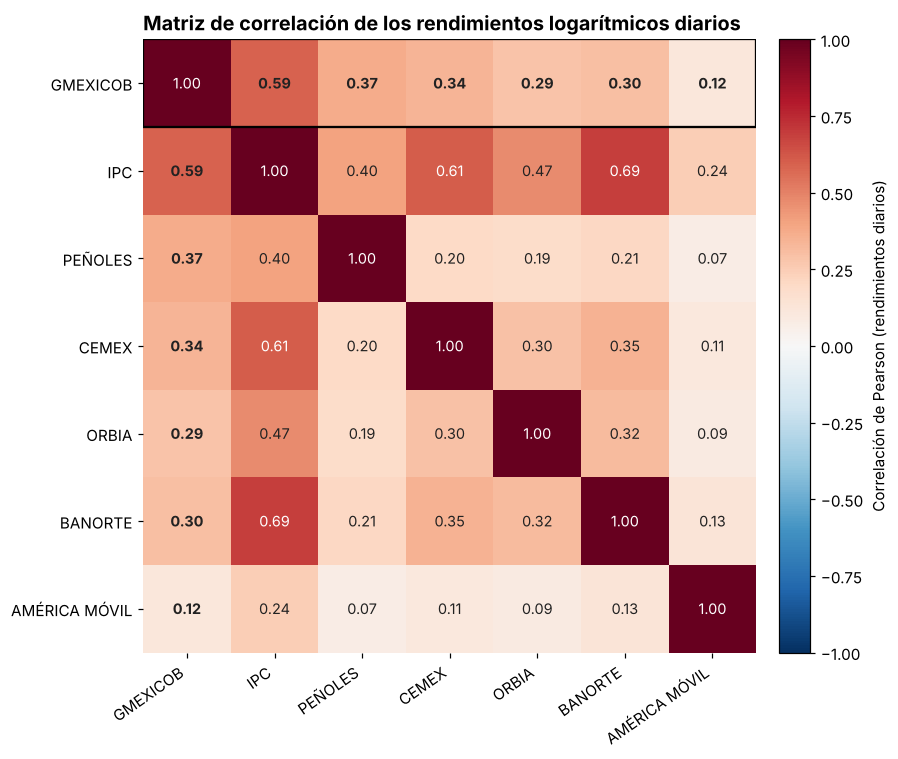

In [4]:
corr = rend.corr()
fig = g4.heatmap(corr, ACTIVO, carpeta=GRAFICAS)
plt.show()

In [5]:
rk = u4.ranking(corr, ACTIVO)
top5 = list(rk["Activo"].head(5))
top3 = [a for a in rk["Activo"] if a != MERCADO][:3]
t = rk[["Lugar", "Activo", "Correlación"]].copy()
t["Correlación"] = t["Correlación"].map(f2)
t["Grupo"] = ["Top 5" if a in top5 else "" for a in t["Activo"]]
md_out(f"**Correlación de {ACTIVO} con cada activo, de mayor a menor**")
tabla(t)
md_out(
    f"Los cinco más correlacionados con {ACTIVO} son: **{', '.join(top5)}**. "
    f"Sin contar al índice, las tres empresas más correlacionadas son **{', '.join(top3)}**; son las que usamos en la Parte 3."
)

**Correlación de GMEXICOB con cada activo, de mayor a menor**

|   Lugar | Activo        |   Correlación | Grupo   |
|--------:|:--------------|--------------:|:--------|
|       1 | IPC           |          0.59 | Top 5   |
|       2 | PEÑOLES       |          0.37 | Top 5   |
|       3 | CEMEX         |          0.34 | Top 5   |
|       4 | BANORTE       |          0.3  | Top 5   |
|       5 | ORBIA         |          0.29 | Top 5   |
|       6 | AMÉRICA MÓVIL |          0.12 |         |

Los cinco más correlacionados con GMEXICOB son: **IPC, PEÑOLES, CEMEX, BANORTE, ORBIA**. Sin contar al índice, las tres empresas más correlacionadas son **PEÑOLES, CEMEX, BANORTE**; son las que usamos en la Parte 3.

In [6]:
cmp_ = u4.corr_precios_vs_rend(precios, rend, ACTIVO)
cmp_["En precios"] = cmp_["En precios"].map(f2)
cmp_["En rendimientos"] = cmp_["En rendimientos"].map(f2)
md_out(f"**La misma correlación medida en precios y en rendimientos ({ACTIVO} contra cada activo)**")
tabla(cmp_)

b, r2 = u4.beta(rend, ACTIVO, MERCADO)
md_out(
    f"**Exposición al mercado:** la beta de {ACTIVO} contra el {MERCADO} es **{b:.2f}**: cuando el índice sube o baja 1% en un día, "
    f"la acción se mueve en promedio {b:.2f}% en la misma dirección. El R² es {r2:.2f}: el mercado explica "
    f"{r2:.0%} de la variación diaria de la acción, y el {1 - r2:.0%} restante es riesgo propio de la empresa."
)

**La misma correlación medida en precios y en rendimientos (GMEXICOB contra cada activo)**

| Activo        |   En precios |   En rendimientos |
|:--------------|-------------:|------------------:|
| IPC           |         0.88 |              0.59 |
| PEÑOLES       |         0.79 |              0.37 |
| CEMEX         |         0.65 |              0.34 |
| ORBIA         |        -0.53 |              0.29 |
| BANORTE       |         0.93 |              0.3  |
| AMÉRICA MÓVIL |         0.85 |              0.12 |

**Exposición al mercado:** la beta de GMEXICOB contra el IPC es **1.30**: cuando el índice sube o baja 1% en un día, la acción se mueve en promedio 1.30% en la misma dirección. El R² es 0.35: el mercado explica 35% de la variación diaria de la acción, y el 65% restante es riesgo propio de la empresa.

**Lectura de la matriz.**

- **GMEXICOB se mueve más con el mercado en general que con cualquier empresa en particular.** Su correlación con el IPC es 0.59; con las cinco empresas va de 0.12 a 0.37. Comparte con ellas el ánimo del mercado mexicano, pero no el negocio.
- **Peñoles es la empresa más correlacionada (0.37)** porque también es minera y depende de los precios de los metales. Aun así, la relación es débil: Peñoles vive sobre todo de la plata y el oro, y Grupo México del cobre y de sus ferrocarriles.
- **Cemex (0.34) y Banorte (0.30) le siguen:** son empresas cíclicas que suben y bajan con la economía y el apetito por riesgo en México. Banorte es, de hecho, el activo más ligado al IPC (0.69).
- **América Móvil casi no se relaciona con GMEXICOB (0.12):** vende telefonía e internet, un servicio que la gente sigue pagando en cualquier ciclo económico.
- **La tabla de precios contra rendimientos muestra por qué se usan rendimientos.** Banorte tiene una correlación de 0.93 en precios, pero solo 0.30 en rendimientos, porque las dos acciones subieron en el periodo. Orbia aparece con −0.53 en precios solo porque bajó mientras GMEXICOB subía, aunque día a día se mueven en la misma dirección (0.29).

## Parte 3 | Rendimiento acumulado

**¿Qué se hizo?** Comparamos cuánto habrían crecido 100 pesos invertidos en GMEXICOB, en sus tres activos más correlacionados y en el IPC durante el mismo periodo.

**¿Cómo se hizo?** Dividimos cada serie de precios entre su primer valor y la multiplicamos por 100 (base 100). Usamos escala logarítmica para que los cambios porcentuales se vean del mismo tamaño en todo el periodo. Para ver en qué periodos se separan los activos, calculamos también la correlación móvil de un año.

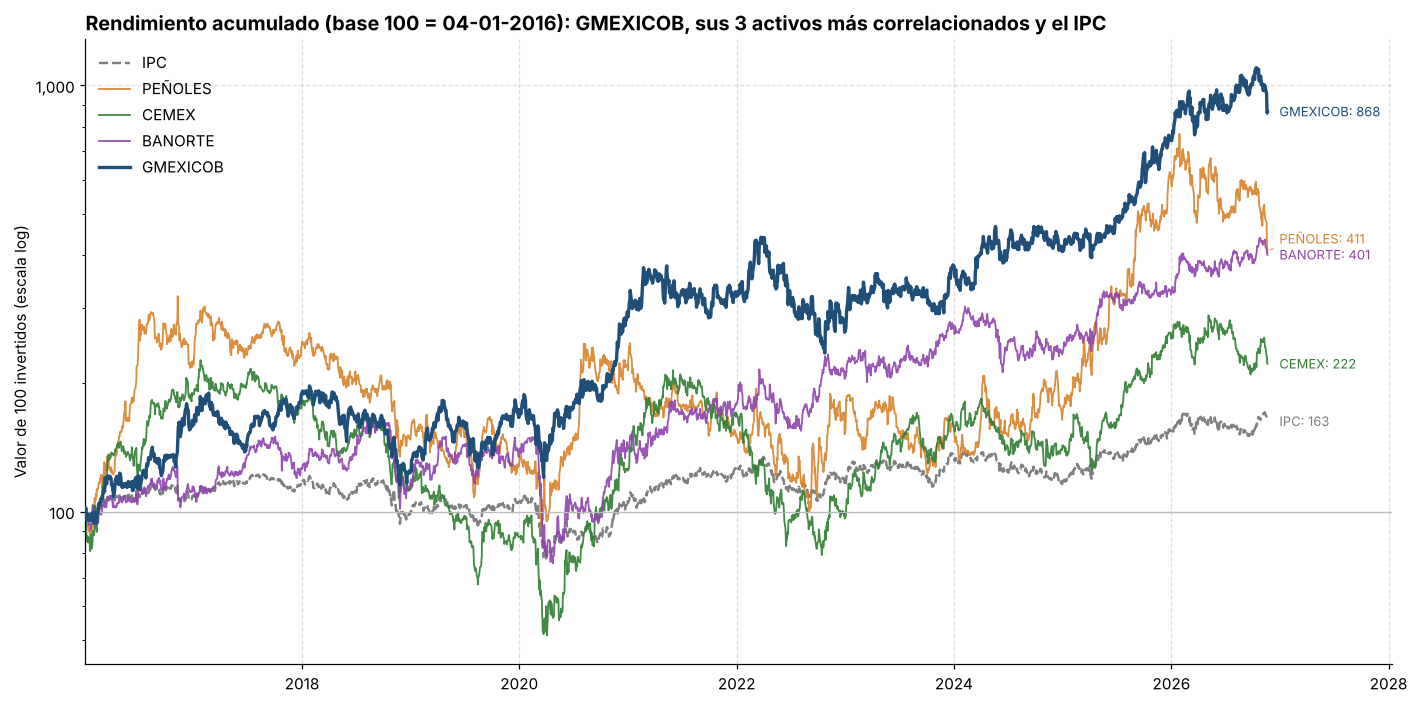

| Activo   |   Base 100 al final | Rend. total   | Rend. anual compuesto   | Volatilidad anual   | Caída máxima   |
|:---------|--------------------:|:--------------|:------------------------|:--------------------|:---------------|
| GMEXICOB |                 868 | +768.3%       | +22.0%                  | 34.9%               | -46.5%         |
| PEÑOLES  |                 411 | +310.8%       | +13.9%                  | 44.8%               | -71.8%         |
| CEMEX    |                 222 | +122.2%       | +7.6%                   | 36.8%               | -77.4%         |
| BANORTE  |                 401 | +300.6%       | +13.6%                  | 33.0%               | -54.3%         |
| IPC      |                 163 | +63.0%        | +4.6%                   | 15.9%               | -36.3%         |

In [7]:
fig = g4.acumulado_base100(precios, ACTIVO, top3, MERCADO, carpeta=GRAFICAS)
plt.show()

d = u4.desempeno(precios[[ACTIVO] + top3 + [MERCADO]])
for c in ["Base 100 al final"]:
    d[c] = d[c].map(lambda v: f"{v:,.0f}")
for c in ["Rend. total", "Rend. anual compuesto", "Caída máxima"]:
    d[c] = d[c].map(lambda v: pct(v, True))
d["Volatilidad anual"] = d["Volatilidad anual"].map(pct)
tabla(d)

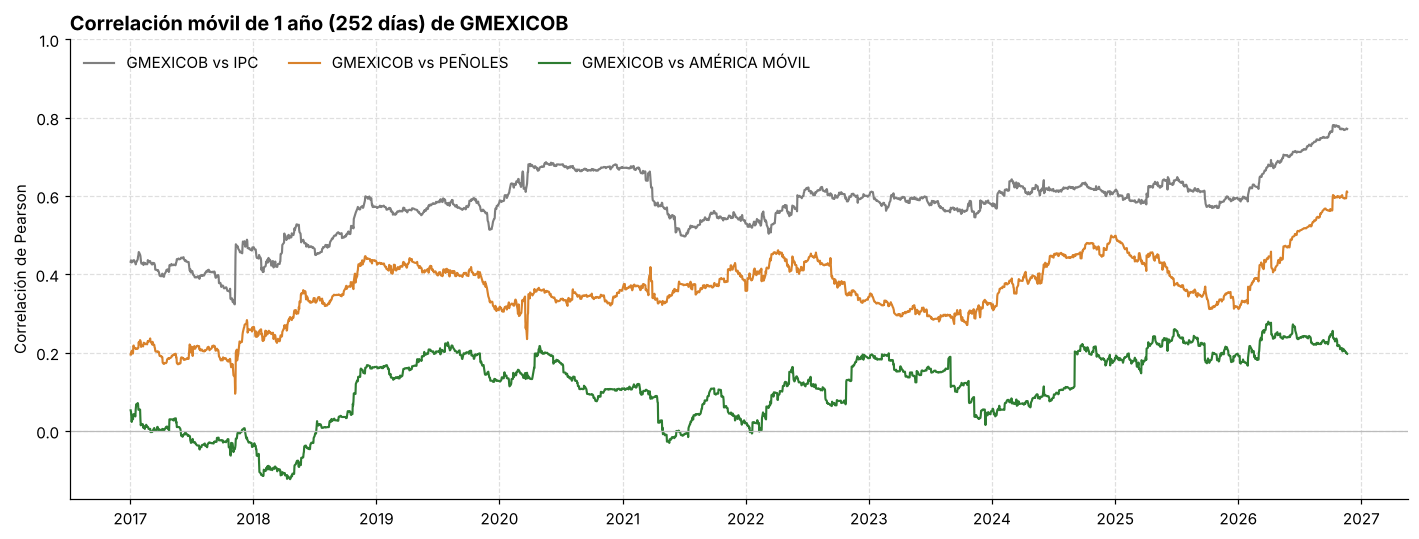

In [8]:
menos = rk["Activo"].iloc[-1]
cm = u4.corr_movil(rend, ACTIVO, [MERCADO, top3[0], menos])
fig = g4.correlacion_movil(cm, ACTIVO, carpeta=GRAFICAS)
plt.show()

**¿Qué activos se mueven juntos?** En las caídas generales, todos bajan al mismo tiempo. En 2018, con la guerra comercial, GMEXICOB cayó 34%, Peñoles 39%, Cemex 35% y el IPC 16%. En el desplome de febrero a abril de 2020, la correlación de GMEXICOB con el IPC subió a 0.73, contra 0.52 en todo el periodo de 2016 a 2019.

**¿En qué periodos se separan?**

- **2019 y 2020:** GMEXICOB subió mientras Peñoles y Cemex caían (en 2019: +34.7% contra −13.4% y −22.6%). Incluso en el peor día de la pandemia, el 23 de marzo de 2020, GMEXICOB seguía arriba de su punto de partida (120), mientras el IPC estaba en 78 y Cemex en 52. El cobre se recuperó antes que la economía.
- **2021 y 2022:** se separó del mercado en sentido contrario. En 2021 el IPC subió 20.9% y GMEXICOB solo 13.6%, y en 2022 la acción cayó 18.8% por la corrección del cobre.
- **2025 y 2026:** Peñoles se disparó 256% en 2025 con el alza de la plata y el oro, y en 2026 devolvió parte (−31.9% en el año). Al mismo tiempo, la correlación de GMEXICOB con el IPC llegó a su nivel más alto del periodo (0.78 en octubre de 2026). Una explicación es que Grupo México se volvió la empresa más valiosa de la BMV y hoy pesa más dentro del índice.

**¿Le ganó al mercado?** Sí, con mucha ventaja. 100 pesos invertidos en enero de 2016 valen 868 en GMEXICOB y 163 en el IPC: 22.0% contra 4.6% anual compuesto. También superó a Peñoles (411), Banorte (401), América Móvil (259), Cemex (222) y Orbia (69). El costo fue más riesgo: su volatilidad (34.9% anual) es más del doble que la del IPC, y llegó a caer 46.5% desde un máximo.

### Diversificación y exposición al riesgo

Para medir si combinar GMEXICOB con otro activo reduce el riesgo, armamos un portafolio 50/50 con cada uno y comparamos su volatilidad contra el promedio de las volatilidades de los dos activos. Entre más baja la correlación, mayor la reducción.

In [9]:
dv, vol_gm = u4.diversificacion(rend, ACTIVO)
dv["Correlación"] = dv["Correlación"].map(f2)
for c in ["Vol. del otro activo", "Vol. 50/50"]:
    dv[c] = dv[c].map(pct)
dv["Reducción vs promedio"] = dv["Reducción vs promedio"].map(lambda v: pct(v))
md_out(f"Volatilidad anual de {ACTIVO} sola: **{vol_gm:.1f}%**.")
tabla(dv)

Volatilidad anual de GMEXICOB sola: **34.9%**.

| Activo        |   Correlación | Vol. del otro activo   | Vol. 50/50   | Reducción vs promedio   |
|:--------------|--------------:|:-----------------------|:-------------|:------------------------|
| AMÉRICA MÓVIL |          0.12 | 26.1%                  | 23.0%        | 24.7%                   |
| ORBIA         |          0.29 | 33.1%                  | 27.3%        | 19.7%                   |
| BANORTE       |          0.3  | 33.0%                  | 27.4%        | 19.4%                   |
| CEMEX         |          0.34 | 36.8%                  | 29.4%        | 18.1%                   |
| PEÑOLES       |          0.37 | 44.8%                  | 33.1%        | 16.9%                   |
| IPC           |          0.59 | 15.9%                  | 23.1%        | 9.2%                    |

- **Combinar GMEXICOB con cualquier otro activo reduce el riesgo**, porque ninguna correlación llega a 1. La reducción es mayor entre menos correlacionados están: con América Móvil (0.12), el portafolio 50/50 tiene una volatilidad de 23.0%, 24.7% menos que el promedio de las dos acciones. Con el IPC, la reducción es de solo 9.2%.
- **Para un portafolio de acciones mexicanas, GMEXICOB sí sirve para diversificar:** su correlación con bancos, telecomunicaciones o industria es baja. A cambio, agrega exposición a un solo factor, el precio del cobre, y una beta de 1.30 que amplifica los movimientos del mercado.
- **La protección es menor en las crisis.** En la caída de 2020 la correlación con el IPC subió a 0.73, y en 2026 está en su nivel más alto. Justo cuando más se necesita la diversificación, los activos tienden a caer juntos.

## Conclusión de la entrega 4

GMEXICOB está ligada al mercado mexicano (correlación de 0.59 y beta de 1.30), pero no a las demás empresas que analizamos: su riesgo principal es propio y viene del cobre. Desde 2016 le ganó con mucha ventaja al IPC y a las cinco empresas, a cambio de una volatilidad dos veces mayor. Para diversificar conviene combinarla con empresas defensivas como América Móvil, y no con otras mineras o industriales, sin olvidar que en las crisis las correlaciones suben y la protección se reduce.